In [ ]:

import pandas as pd
from sklearn.datasets import load_iris

# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add species column
df['species'] = iris.target_names[iris.target]

print("Dataset created successfully!")
print(df.head())


Dataset created successfully!
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


In [ ]:

# Separate input features and target

X = df.drop('species', axis=1)

y = df['species']

print("Input features:")
print(X.head())

print("\nTarget output:")
print(y.head())


Input features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target output:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [ ]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:

from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the number of samples
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [ ]:

# Import KNN algorithm
from sklearn.neighbors import KNeighborsClassifier

# Create the model
model = KNeighborsClassifier(n_neighbors=5)

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [ ]:

# Predict flower species
y_pred = model.predict(X_test)

# Display actual and predicted values
print("Actual species:")
print(y_test.values[:10])

print("\nPredicted species:")
print(y_pred[:10])


Actual species:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']

Predicted species:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [ ]:

from sklearn.metrics import accuracy_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 100.0 %


In [ ]:

from sklearn.metrics import confusion_matrix, classification_report

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

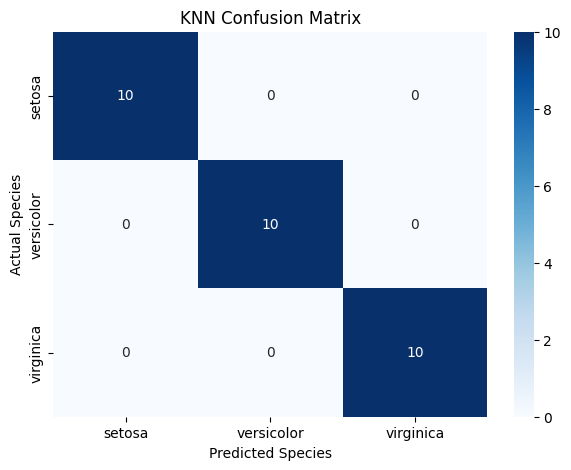

In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

# Load dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target_names[iris.target]

# Separate features and target
X = df.drop('species', axis=1)
y = df['species']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train model
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=iris.target_names)

# Display confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("KNN Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [2]:
from google.colab import files
files.download("confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Scale training and testing data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

# Divide training data into 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Test K values from 1 to 15
k_values = range(1, 16)
cv_results = []

for k in k_values:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        pipeline, X_train, y_train,
        cv=cv, scoring="accuracy"
    )

    cv_results.append(scores.mean())

# Display results
for k, score in zip(k_values, cv_results):
    print(f"K={k}: {score*100:.2f}%")

best_k = list(k_values)[int(np.argmax(cv_results))]
print("\nBest K value:", best_k)

K=1: 94.17%
K=2: 95.00%
K=3: 96.67%
K=4: 95.83%
K=5: 95.83%
K=6: 94.17%
K=7: 93.33%
K=8: 94.17%
K=9: 95.83%
K=10: 95.83%
K=11: 95.00%
K=12: 95.83%
K=13: 95.00%
K=14: 92.50%
K=15: 92.50%

Best K value: 3


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Train KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

# Train Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

# Compare accuracy
print("KNN Accuracy:", accuracy_score(y_test, knn_pred) * 100, "%")
print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred) * 100, "%")

KNN Accuracy: 100.0 %
Decision Tree Accuracy: 93.33333333333333 %


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Create the final model
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=3))
])

# Train using the complete training dataset
final_model.fit(X_train, y_train)

# Predict species for test data
final_pred = final_model.predict(X_test)

# Calculate test accuracy
final_accuracy = accuracy_score(y_test, final_pred)

print("Final model trained successfully!")
print("Best K value: 3")
print("Final Test Accuracy:", final_accuracy * 100, "%")

Final model trained successfully!
Best K value: 3
Final Test Accuracy: 93.33333333333333 %


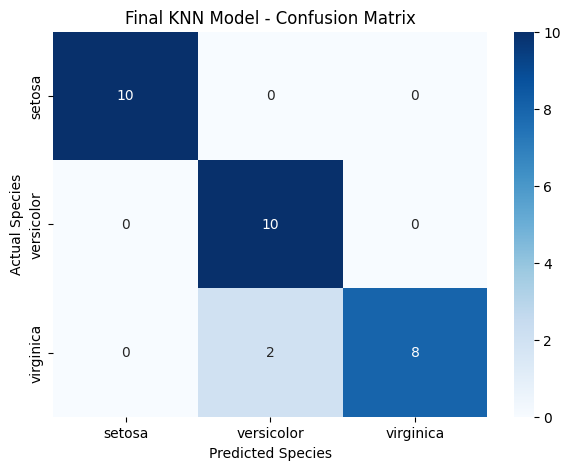

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [6]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    final_pred,
    labels=iris.target_names
)

# Display confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Final KNN Model - Confusion Matrix")
plt.show()

# Display classification report
print("Classification Report:")
print(classification_report(y_test, final_pred))

In [7]:
import joblib

# Save the trained model
joblib.dump(final_model, "iris_knn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [8]:
from google.colab import files

files.download("iris_knn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import classification_report

print("KNN Classification Report:")
print(classification_report(y_test, knn_pred))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, dt_pred))

KNN Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


Decision Tree Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [ ]:
# Measurements of a new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]

# Predict its species
prediction = knn.predict(new_flower)

print("Predicted flower species:", prediction[0])

Predicted flower species: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [9]:
import joblib
import pandas as pd

# Load the saved model
loaded_model = joblib.load("iris_knn_model.pkl")

# Give a new flower's measurements
sample = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

# Predict the species
prediction = loaded_model.predict(sample)

print("Predicted flower species:", prediction[0])

Predicted flower species: setosa


In [10]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Create input boxes
sepal_length = widgets.FloatText(
    value=5.1, description="Sepal Length:"
)

sepal_width = widgets.FloatText(
    value=3.5, description="Sepal Width:"
)

petal_length = widgets.FloatText(
    value=1.4, description="Petal Length:"
)

petal_width = widgets.FloatText(
    value=0.2, description="Petal Width:"
)

# Create prediction button
predict_button = widgets.Button(
    description="Predict Flower",
    button_style="success"
)

# Area to display prediction
output = widgets.Output()

# Display interface
display(
    widgets.VBox([
        widgets.HTML("<h2>🌸 Iris Flower Predictor</h2>"),
        sepal_length,
        sepal_width,
        petal_length,
        petal_width,
        predict_button,
        output
    ])
)

In [13]:
import numpy as np
from IPython.display import display, HTML, clear_output

# Descriptions of the three Iris species
flower_info = {
    "setosa": "Iris Setosa: Usually has smaller petals and is easily distinguished from the other species.",
    "versicolor": "Iris Versicolor: Has medium-sized petals compared with the other two species.",
    "virginica": "Iris Virginica: Generally has larger petals than the other two species."
}

def predict_flower(button):
    with output:
        clear_output()

        # Collect measurements
        values = [
            sepal_length.value,
            sepal_width.value,
            petal_length.value,
            petal_width.value
        ]

        # Check for invalid numbers
        if not all(np.isfinite(values)):
            display(HTML(
                "<h3 style='color:red;'>Please enter valid numbers.</h3>"
            ))
            return

        # Check measurements against dataset ranges
        minimum = X.min().values
        maximum = X.max().values

        if any(v < lo or v > hi
               for v, lo, hi in zip(values, minimum, maximum)):
            display(HTML(
                "<h3 style='color:red;'>Invalid measurements!</h3>"
                "<p>Please enter values within the Iris dataset ranges.</p>"
            ))
            return

        # Prepare input
        measurements = pd.DataFrame(
            [values],
            columns=X.columns
        )

        # Predict species
        prediction = loaded_model.predict(measurements)[0]
        description = flower_info[prediction]

        # Display attractive result
        display(HTML(f"""
        <div style="
            background-color:#e8f5e9;
            padding:20px;
            border-radius:12px;
            text-align:center;
            border:2px solid #66bb6a;
        ">
            <h2 style="color:#2e7d32;">
                🌸 Prediction Result
            </h2>
            <h1 style="color:#1b5e20;">
                {prediction.upper()}
            </h1>
            <p style="color:#333;font-size:16px;">
                {description}
            </p>
        </div>
        """))

# Remove the previous button callback, if registered
predict_button.on_click(predict_flower, remove=True)

# Connect the upgraded function
predict_button.on_click(predict_flower)

print("Upgraded predictor is ready!")

Upgraded predictor is ready!


In [12]:
def predict_flower(button):
    with output:
        clear_output()

        # Collect the four measurements
        measurements = pd.DataFrame(
            [[
                sepal_length.value,
                sepal_width.value,
                petal_length.value,
                petal_width.value
            ]],
            columns=X.columns
        )

        # Predict using our trained model
        prediction = loaded_model.predict(measurements)

        print("🌸 Predicted Flower Species:")
        print(prediction[0].upper())


# Connect button to prediction function
predict_button.on_click(predict_flower)